# TSIA202a - Second Practice Session : Spectral density estimation and periodogram Maxime Appert
The goal of this second session is to provide a power spectral density estimator of a real, zero-mean, weakly stationary process $X_t$. We suppose that we have access to $n$ observations and we will use the FFT algorithm (that implements the DFT) using `numpy.fft.module`.
Recall (from the course) that the periodogram of the observations $X_0, \dots, X_{n-1}$ can be given as:
$$
I_n(\lambda) = \frac{1}{2\pi n}|\sum_{k=0}^{n-1} X_k e^{i\lambda k}|^2
$$

Moreover, the Hertglotz theorem provides a relation between the empirical autocovariance $\hat{\gamma}_n$ and the periodogram $I_n$:
$$
\hat{\gamma}_n(k) = \int_{0}^{2\pi}e^{i\lambda k}I_n({\lambda})d\lambda
$$

1. For a given $m \geq n$  we denote also the DFT as:
$$
DFT(X,m)(k) = \sum_{h=0}^{n-1}X_he^{-2i\pi\frac{kh}{m}}
$$
Show the following relation:
$$I_n(\frac{2\pi k}{m}) = \frac{1}{2\pi n} |DFT(X,m)(k)|^2$$
2. provide a script that compute those $I_n(\frac{2\pi k}{m})$ for the time series mentioned in the first practice session
3. Show that $I_n(\lambda) = \frac{1}{2\pi} \sum_{k=0}^{n-1} \hat{\gamma}_n(k)e^{-i\lambda k}$
4. How to choose $m$ in order to get a simple relation between $\hat{\gamma}_n(k)$ and $I_n(\frac{2\pi k}{m})$ ? At the end, given a specific $\tilde{m}$ show that:
$$
\hat{\gamma}_n(k) = \frac{1}{n} IDFT\left(\left|DFT(X, \tilde{m})\right|^2, \tilde{m}\right)(k)
$$ Try this estimator on the autocovariance of previous time series of the first session.

5. In the case of white noise, estimate the variance of the periodogram for several values of $n$ and discuss about it.




1) This first result is obvious and results from the definition of DFT.
$$
I_n(\frac{2\pi k}{m}) = \frac{1}{2\pi n}|\sum_{k=0}^{n-1} X_k e^{i\frac{2\pi k}{m} k}|^2
$$
This can be further refined to:
$$
I_n(\frac{2\pi k}{m}) = \frac{1}{2\pi n} | DFT(X,m)(k) |^2
$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(100)

<ipython-input-2-b7a046e611b4>:18: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  return [100 + np.sum(z_t[i - k + 10] * 1 / 2 ** k for k in range(11)) for i in range(size)]


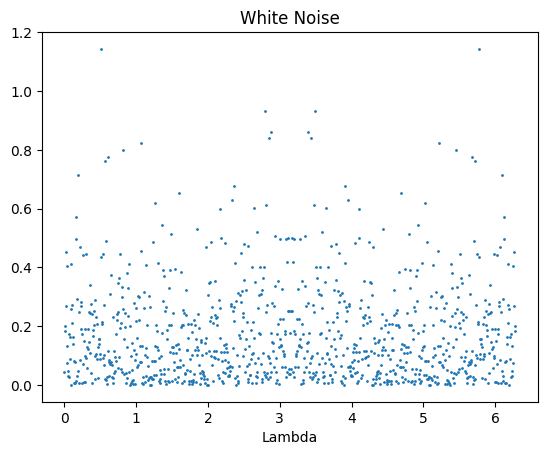

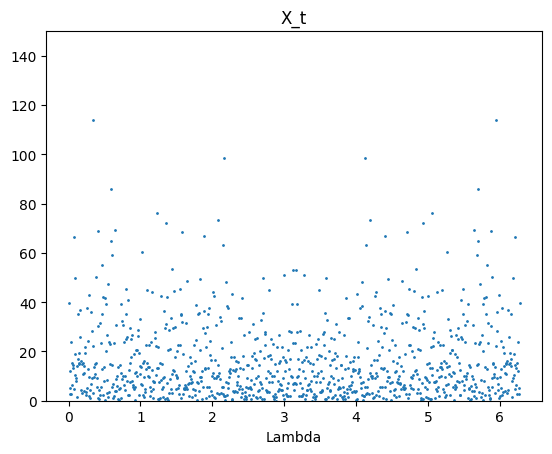

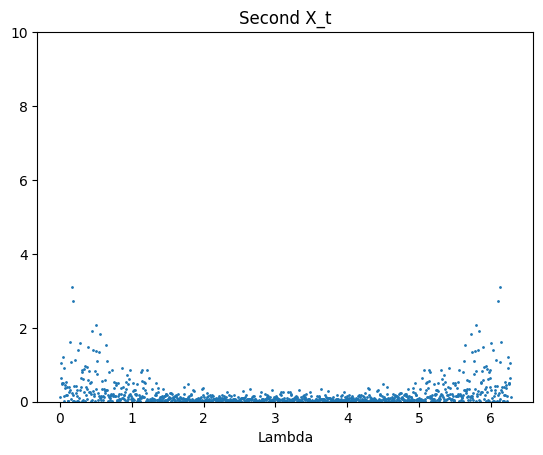

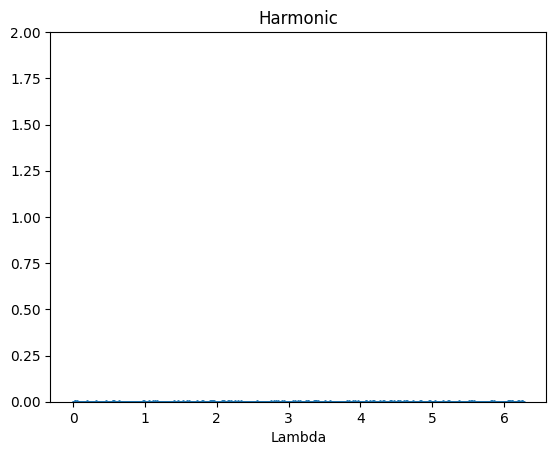

In [ ]:
def In(X):
    return 1/(2*np.pi*len(X))*np.square(np.abs(np.fft.fft(X)))

def generate_white_noise_series(size=1000):
    return np.random.normal(0, 1, size)

def backshift(x, k):
    shifted_array = np.zeros(k)
    truncated_array = x[:-k] if k > 0 else x
    return np.concatenate((shifted_array, truncated_array))

def X_t(size=1000):
    z_t = np.random.normal(0, 1, size)
    return 100+10* z_t+ backshift(z_t, 1)

def X_t_1(size=1000):
    z_t = np.random.normal(0, 1, size + 10)
    return [100 + np.sum(z_t[i - k + 10] * 1 / 2 ** k for k in range(11)) for i in range(size)]

def X_t_2(size=1000):
    z_t = np.random.normal(0,1,size)
    phi_0 = np.random.uniform(0, 2*np.pi, size)
    return [[z_t[x] + 2*np.cos(x+phi_0[0])] for x in range(size)]

length = np.arange(0, 2*np.pi, step=2*np.pi/1000)
white_noise_In = In(generate_white_noise_series())
X_t_In = In(X_t())
X_t_1_In = In(X_t_1())
harmonic_In = In(X_t_2())

plt.figure()
plt.title("White Noise")
plt.xlabel('Lambda')
plt.plot(length, white_noise_In, 'o', markersize=1)
plt.show()

plt.figure()
plt.title("X_t")
plt.xlabel('Lambda')
plt.plot(length, X_t_In, 'o', markersize=1)
plt.ylim(0,150)
plt.show()

plt.figure()
plt.title("Second X_t")
plt.xlabel('Lambda')
plt.plot(length, X_t_1_In, 'o', markersize=1)
plt.ylim(0,10)
plt.show()

plt.figure()
plt.title("Harmonic")
plt.xlabel('Lambda')
plt.plot(length, harmonic_In, 'o', markersize=1)
plt.ylim(0,2)
plt.show()

See Image Question 3 and 4 TP2


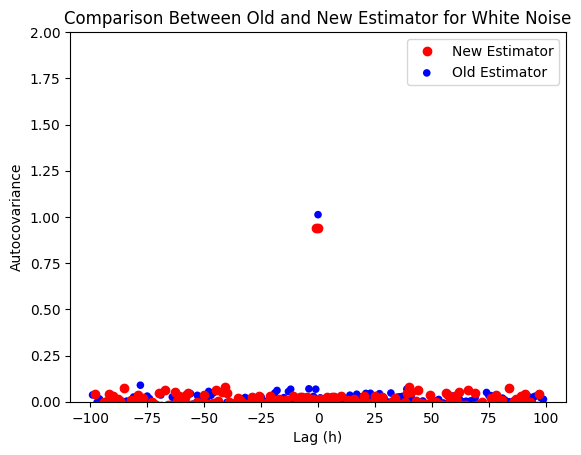

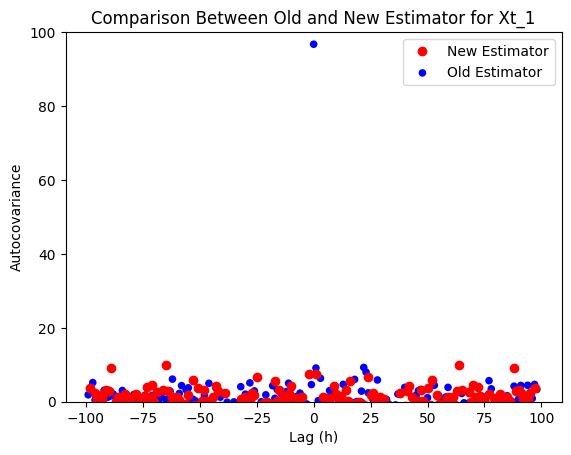

<ipython-input-2-b7a046e611b4>:18: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  return [100 + np.sum(z_t[i - k + 10] * 1 / 2 ** k for k in range(11)) for i in range(size)]


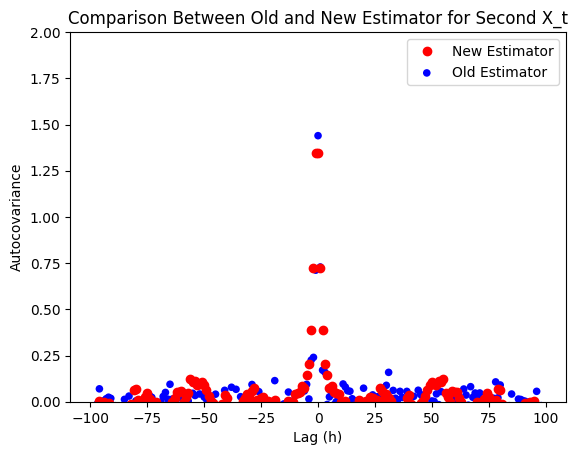

In [ ]:
def calculate_empirical_autocovariance(x, lag):
    n = len(x)
    mean_x = np.mean(x)
    sum_term = lambda t: (x[t + lag] - mean_x) * np.conj(x[t] - mean_x)
    summation = lambda start, finish: sum([sum_term(t) for t in range(start, finish)])

    if np.abs(lag) > n - 1:
        return 0
    elif lag >= 0:
        return (1/n) * summation(0, n - lag)
    else:
        return (1/n) * summation(-lag, n)

def new_estimator(x, lag):
    mean_centered = x - np.mean(x)
    spectrum = np.square(np.abs(np.fft.fft(mean_centered, n=len(x))))
    inverse_transform = np.fft.ifft(spectrum) / len(x)
    truncated_inverse_transform = inverse_transform[:lag + 1]
    reversed_truncated_inverse_transform = np.flip(truncated_inverse_transform)
    concatenated_result = np.concatenate([reversed_truncated_inverse_transform[1:], truncated_inverse_transform])
    return np.real(concatenated_result)

def plot_autocovariance_estimator_comparison(hs, empirical_autocovs, new_estimator_autocovs, series_length, title, ylim):
    plt.figure()
    line_label = "New Estimator"
    plt.plot(hs, new_estimator_autocovs, label=line_label, marker='o', color='red', linestyle='')
    plt.scatter(hs, empirical_autocovs, marker='o', label="Old Estimator", s=30, edgecolors='none', color='blue')
    plt.ylim(0, 1.5)
    plt.title(f'Comparison Between Old and New Estimator for {title}')
    plt.xlabel('Lag (h)')
    plt.ylabel('Autocovariance')
    plt.legend()
    plt.ylim(0, ylim)
    plt.show()

series_length = 100
hs_autocov = np.arange(-(series_length-1), series_length)
empirical_autocovs = [calculate_empirical_autocovariance(generate_white_noise_series(), h) for h in hs_autocov]
theoretical_autocovs = new_estimator(generate_white_noise_series(), 99)
plot_autocovariance_estimator_comparison(hs_autocov, empirical_autocovs, theoretical_autocovs, series_length, "White Noise",2)

series_length = 100
hs_autocov = np.arange(-(series_length-1), series_length)
empirical_autocovs = [calculate_empirical_autocovariance(X_t(), h) for h in hs_autocov]
theoretical_autocovs = new_estimator(X_t(), 99)
plot_autocovariance_estimator_comparison(hs_autocov, empirical_autocovs, theoretical_autocovs, series_length, "Xt_1",100)

series_length = 100
hs_autocov = np.arange(-(series_length-1), series_length)
empirical_autocovs = [calculate_empirical_autocovariance(X_t_1(), h) for h in hs_autocov]
theoretical_autocovs = new_estimator(X_t_1(), 99)
plot_autocovariance_estimator_comparison(hs_autocov, empirical_autocovs, theoretical_autocovs, series_length, "Second X_t",2)

In [ ]:
variances = [0.1, 1, 10, 100]
n_list = [10, 100, 1000, 10000, 100000]

for variance in variances:
    for n in n_list:
        periodogram_variance = np.var(In(np.random.normal(0, np.sqrt(variance),n)))
        print(f"variance:{variance}, n:{n}, periodogram variance:{periodogram_variance},  difference between variance and square root of periodogram variance * 2 * pi: {variance - np.sqrt(periodogram_variance*2*np.pi)}")


variance:0.1, n:10, periodogram variance:0.00022133667199781518,  difference between variance and square root of periodogram variance * 2 * pi: 0.06270791873015533
variance:0.1, n:100, periodogram variance:0.0002504012286890687,  difference between variance and square root of periodogram variance * 2 * pi: 0.06033493576207305
variance:0.1, n:1000, periodogram variance:0.00023789215811600845,  difference between variance and square root of periodogram variance * 2 * pi: 0.06133838450649343
variance:0.1, n:10000, periodogram variance:0.00025979898459070074,  difference between variance and square root of periodogram variance * 2 * pi: 0.05959746093621756
variance:0.1, n:100000, periodogram variance:0.0002607059179368042,  difference between variance and square root of periodogram variance * 2 * pi: 0.05952700167920228
variance:1, n:10, periodogram variance:0.03939458979900301,  difference between variance and square root of periodogram variance * 2 * pi: 0.5024826557722208
variance:1, n:

We can see here the relation

$$
var(I_n) = \frac {\sigma^4} {{2\pi}^2}
$$